# Practical 6A — Q-Learning in a Maze

Train an agent to reach the goal in a small maze. Q-learning improves action values through rewards and penalties; no external dataset is needed.

**Run the cells from top to bottom.** The dataset is generated inside this notebook before the practical begins.

## 1. Install / import requirements

If a package is missing, run `!pip install pandas numpy matplotlib seaborn scikit-learn statsmodels openpyxl requests xgboost` in a notebook cell. Most environments already have the common packages.

In [1]:
from pathlib import Path
Path('data').mkdir(exist_ok=True)


## 2. Dataset

No separate CSV is needed for this practical. The code uses the built-in dataset / maze environment directly.

## 3. Practical implementation

The following cells perform the analysis and show the output.

In [2]:
import numpy as np

maze = np.array([[0, 0, 0, 1, 0],      # 0 = free, 1 = wall
                 [1, 1, 0, 1, 0],
                 [0, 0, 0, 0, 0],
                 [0, 1, 1, 1, 0],
                 [0, 0, 0, 0, 0]])
start, goal = (0, 0), (4, 4)
moves = [(-1, 0), (1, 0), (0, -1), (0, 1)]          # up, down, left, right
Q = np.zeros((5, 5, 4))
alpha, gamma, eps = 0.1, 0.9, 0.2

def step(s, a):
    r, c = s[0] + moves[a][0], s[1] + moves[a][1]
    if not (0 <= r < 5 and 0 <= c < 5) or maze[r, c] == 1:
        return s, -5                                 # hit wall: stay, penalty
    return (r, c), (100 if (r, c) == goal else -1)   # goal reward / step cost

for ep in range(2000):                               # training
    s = start
    while s != goal:
        a = np.random.randint(4) if np.random.rand() < eps else Q[s].argmax()
        s2, r = step(s, a)
        Q[s][a] += alpha * (r + gamma * Q[s2].max() - Q[s][a])
        s = s2

s, path = start, [start]                             # test: follow best actions
while s != goal and len(path) < 30:
    s, _ = step(s, Q[s].argmax()); path.append(s)
print("Learned path:", path)

Learned path: [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]


Path: [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]
Steps: 8
Goal reached: True


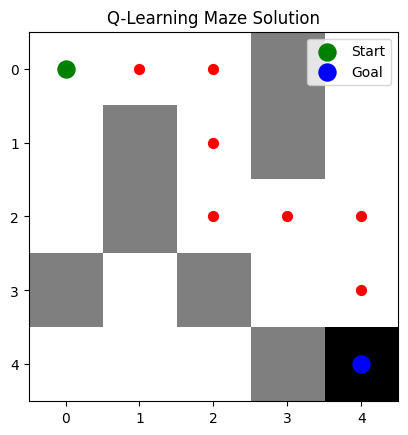

In [3]:
import numpy as np
import random
import matplotlib.pyplot as plt

# Create maze
maze = np.array([
    [0, 0, 0, 1, 0],
    [0, 1, 0, 1, 0],
    [0, 1, 0, 0, 0],
    [1, 0, 1, 0, 0],
    [0, 0, 0, 1, 2]
])

# Start and goal
start = (0, 0)
goal = (4, 4)

# Actions: Up, Down, Left, Right
actions = [0, 1, 2, 3]

# Q-table
q_table = np.zeros((25, 4))

# Movement function
def move(state, action):

    r, c = state

    moves = [
        (-1, 0),
        (1, 0),
        (0, -1),
        (0, 1)
    ]

    dr, dc = moves[action]

    nr, nc = r + dr, c + dc

    if (nr < 0 or nr >= 5 or
        nc < 0 or nc >= 5 or
        maze[nr, nc] == 1):

        return state, -10, False

    if maze[nr, nc] == 2:
        return (nr, nc), 100, True

    return (nr, nc), -1, False


# Q-learning parameters
alpha = 0.1
gamma = 0.9
epsilon = 1.0
episodes = 1000

# Training
for episode in range(episodes):

    state = start

    for step in range(100):

        s = state[0] * 5 + state[1]

        if random.random() < epsilon:
            action = random.choice(actions)
        else:
            action = np.argmax(q_table[s])

        next_state, reward, done = move(state, action)

        ns = next_state[0] * 5 + next_state[1]

        q_table[s, action] += alpha * (
            reward +
            gamma * np.max(q_table[ns]) -
            q_table[s, action]
        )

        state = next_state

        if done:
            break

    epsilon = max(0.01, epsilon * 0.995)


# Test trained agent
state = start
path = [state]

for step in range(100):

    s = state[0] * 5 + state[1]

    action = np.argmax(q_table[s])

    next_state, reward, done = move(state, action)

    state = next_state
    path.append(state)

    if done:
        break

print("Path:", path)
print("Steps:", len(path) - 1)
print("Goal reached:", state == goal)


# Visualize maze
plt.imshow(maze, cmap="gray_r")

for r, c in path:
    plt.scatter(c, r, color="red", s=50)

plt.scatter(start[1], start[0],
            color="green", s=150, label="Start")

plt.scatter(goal[1], goal[0],
            color="blue", s=150, label="Goal")

plt.title("Q-Learning Maze Solution")
plt.legend()
plt.show()